# Classification with missing values and categorical features

We will use the breast-cancer dataset distributed with scikit-learn to compare a neural additive classifier with logistic regression. Along the way, we will handle missing values, inspect predicted probabilities, and save everything needed to make predictions on new rows.


## Prepare the data

We use four measurements and encode the malignant class as 1. The original data are numerical and complete. To demonstrate preprocessing, we hide about 5% of the texture values and create a radius category using fixed cut points. These alterations are part of the example.

The data are split into training, validation, and test sets while preserving the class proportions. The validation set controls neural early stopping; the test set is reserved for the final comparison.

Source: scikit-learn’s [breast-cancer dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset).


In [1]:
import logging
import warnings
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message="You called.*self.log.*logger=True.*")
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.calibration import calibration_curve

raw = load_breast_cancer(as_frame=True)
features = ["mean radius", "mean texture", "mean smoothness", "mean concavity"]
X = raw.data[features].copy()
y = 1 - raw.target.to_numpy()  # malignant = 1
X["radius group"] = pd.cut(X["mean radius"], [-np.inf, 12, 16, np.inf], labels=["small", "medium", "large"])
rng = np.random.default_rng(17)
X.loc[rng.random(len(X)) < 0.05, "mean texture"] = np.nan
X_fit, X_test, y_fit, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=17)
X_train, X_val, y_train, y_val = train_test_split(X_fit, y_fit, test_size=0.25, stratify=y_fit, random_state=18)


In [2]:
raw_test = X_test.copy()
data_quality = pd.DataFrame([
    {"Split": name, "Rows": len(frame), "Malignant fraction": float(np.mean(target)),
     "Missing numeric cells": int(frame[features].isna().sum().sum())}
    for name, frame, target in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]
])
(data_quality).style.hide(axis="index").format(precision=3)


Split,Rows,Malignant fraction,Missing numeric cells
Train,341,0.372,19
Validation,114,0.377,7
Test,114,0.368,6


Split sizes, class proportions, and missing numerical cells before imputation.


## Impute and encode the inputs

We split before learning any imputation or encoding so information from validation and test rows cannot influence those transformations. We replace missing measurements with medians calculated from the training rows. The same medians are reused for validation, test, and future inputs. The NAM learns its scaling and categorical encoding during fitting; logistic regression uses a separate preprocessing pipeline.


In [3]:
medians = X_train[features].median()
def prepare(frame):
    result = frame.copy()
    result[features] = result[features].fillna(medians)
    return result
X_train, X_val, X_test = map(prepare, [X_train, X_val, X_test])

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from nampy.models import NAMClassifier

baseline = make_pipeline(ColumnTransformer([
    ("numeric", StandardScaler(), features),
    ("category", OneHotEncoder(handle_unknown="ignore"), ["radius group"]),
]), LogisticRegression(max_iter=1000))
baseline.fit(X_train, y_train)
model = NAMClassifier(layer_sizes=[16, 8], dropout=0.05,
                      numerical_preprocessing="minmax", categorical_preprocessing="one-hot")
model.fit(X_train, y_train, X_val=X_val, y_val=y_val, max_epochs=120,
          lr=0.01, batch_size=64, patience=20, random_state=17,
          checkpoint_path=tempfile.mkdtemp(), logger=False,
          enable_progress_bar=False, enable_model_summary=False)


## Compare predicted probabilities

We compare predicted probabilities on the held-out rows. Discrimination measures whether the model ranks positive cases above negative cases; calibration measures whether its probabilities agree with observed frequencies. A model can perform well on one and poorly on the other.

In [4]:
probabilities = {"Logistic baseline": baseline.predict_proba(X_test)[:, 1],
                 "NAM": model.predict_proba(X_test)[:, 1]}
(pd.DataFrame([{"Model": name, "Test log loss": log_loss(y_test, p),
               "Test ROC-AUC": roc_auc_score(y_test, p)} for name,p in probabilities.items()])).style.hide(axis="index").format(precision=3)


Model,Test log loss,Test ROC-AUC
Logistic baseline,0.156,0.986
NAM,0.190,0.978


Logistic regression performs better on this test set: its log loss is 0.156, compared with 0.190 for the NAM, and its ROC-AUC is slightly higher. The additional flexibility of the NAM has not improved this comparison. The calibration plot shows where the predicted probabilities agree with the observed frequencies, although its bins are noisy with only 114 test cases.


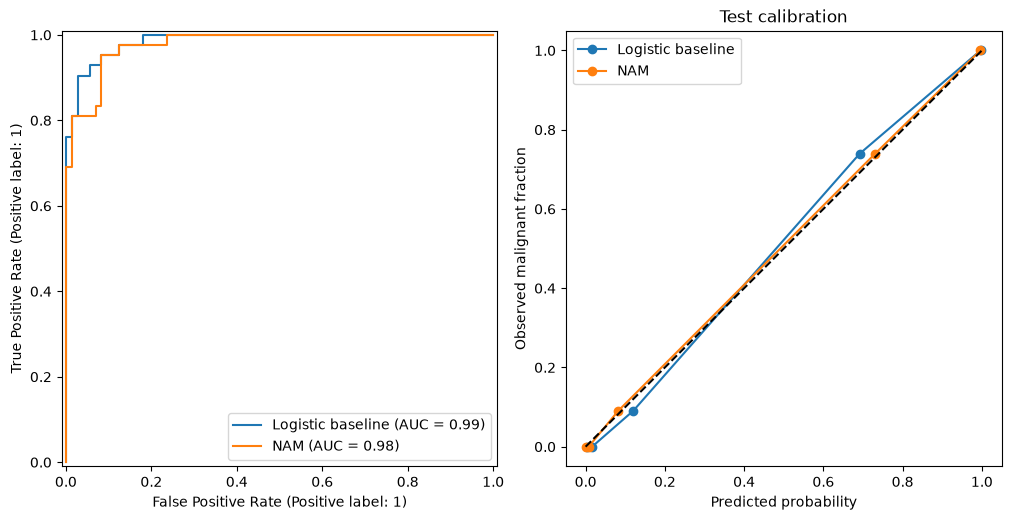

In [5]:
from sklearn.metrics import RocCurveDisplay
figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for name, probability in probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[0])
    observed, predicted = calibration_curve(y_test, probability, n_bins=5, strategy="quantile")
    axes[1].plot(predicted, observed, "o-", label=name)
axes[1].plot([0,1],[0,1], "--", color="black")
axes[1].set(xlabel="Predicted probability", ylabel="Observed malignant fraction", title="Test calibration")
axes[1].legend()
for axis in axes: axis.set_box_aspect(1)
plt.show()
plt.close(figure)


## Interpret the feature effects

The curves are centered contributions to the log-odds of the malignant class. A positive contribution raises those log-odds relative to the training reference. Its effect on probability depends on the other contributions in the row.

Radius appears twice: as a measurement and as a derived category. The model can distribute their shared signal between the two terms, so interpret these curves as one fitted allocation rather than two independent associations.


In [6]:
parts = model.predict_components(X_test, center=True, reference_X=X_train)
parts.validate_additive_reconstruction(atol=1e-5)
importance = model.term_importance(X_test, center=True, reference_X=X_train)
importance[["term", "importance"]].rename(columns={"term": "Term", "importance": "Importance"}).style.hide(axis="index").format({"Importance": "{:.3f}"})


Term,Importance
mean concavity,1.824
mean texture,1.311
mean radius,1.241
radius group,0.746
mean smoothness,0.427


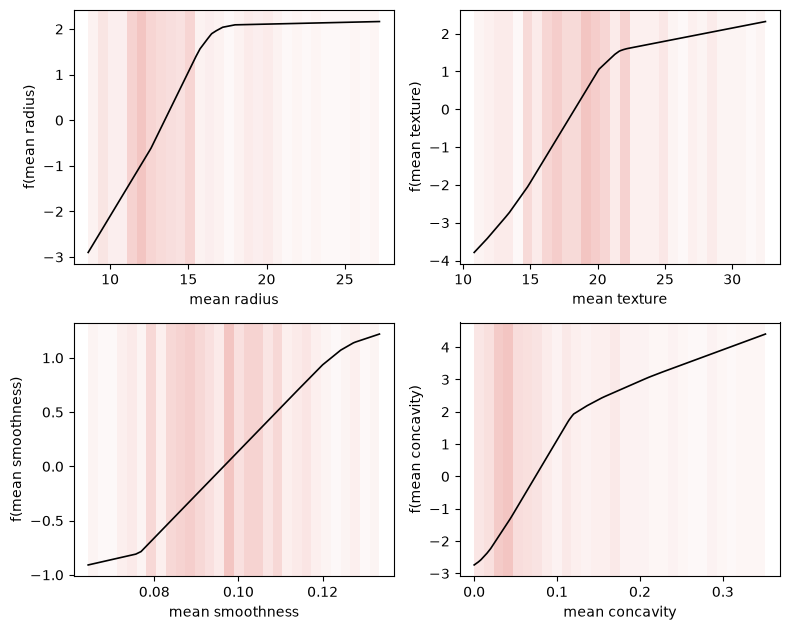

In [7]:
figures = model.plot_terms(X_test, center=True, reference_X=X_train, pages=1)
plt.show()
plt.close("all")


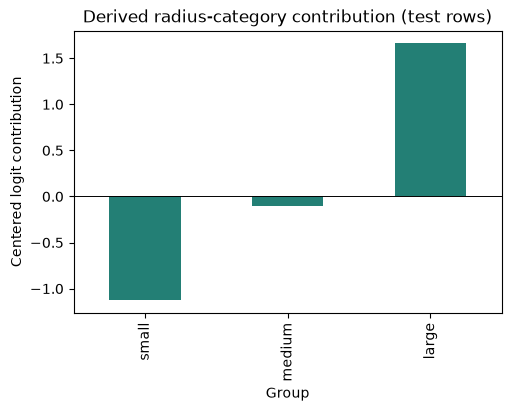

In [8]:
category_terms = [name for name, meta in parts.term_metadata.items() if "radius group" in meta.features]
category_values = sum(np.asarray(parts.terms[name]).reshape(-1) for name in category_terms)
category_frame = pd.DataFrame({"Group": X_test["radius group"].astype(str).to_numpy(), "Contribution": category_values})
means = category_frame.groupby("Group", observed=True).Contribution.mean().reindex(["small", "medium", "large"])
figure, axis = plt.subplots(figsize=(5, 4), constrained_layout=True)
means.plot.bar(ax=axis, color="#237f75")
axis.axhline(0, color="black", lw=.7)
axis.set(ylabel="Centered logit contribution", title="Derived radius-category contribution (test rows)")
plt.show()
plt.close(figure)

Average centered contribution for each radius category on the test rows. The centering reference is the training set.


## Save and reuse the model

To reuse this fit, we need the model and the preprocessing learned from the training data. Save any transformations performed outside the estimator alongside it, then apply the same transformations to new observations.

See the [persistence guide](../howto/persistence.rst) for formats and compatibility details.

In [9]:
from pathlib import Path
from joblib import dump, load
from nampy.models import NAMClassifier

artifact = Path(tempfile.mkdtemp(prefix="nampy-classification-artifact-"))
state = {"medians": medians, "features": features, "columns": X_train.columns.tolist(),
         "radius_edges": [-np.inf, 12, 16, np.inf], "radius_labels": ["small", "medium", "large"]}
model.save_model(artifact / "model.nampy")
dump(state, artifact / "external_preprocessing.joblib")
restored = NAMClassifier.load_model(artifact / "model.nampy")
saved_state = load(artifact / "external_preprocessing.joblib")

def prepare_new(frame, state):
    result = frame[state["features"]].copy()
    result[state["features"]] = result[state["features"]].fillna(state["medians"])
    result["radius group"] = pd.cut(result["mean radius"], state["radius_edges"], labels=state["radius_labels"])
    return result[state["columns"]]

reloaded_probability = restored.predict_proba(prepare_new(raw_test, saved_state))
fresh = pd.DataFrame({"mean radius": [13., 17., np.nan], "mean texture": [np.nan, 22., 18.],
                      "mean smoothness": [.09, .12, .1], "mean concavity": [.05, .15, .07]})
fresh_inputs = prepare_new(fresh, saved_state)
(pd.DataFrame({"Predicted class": restored.predict(fresh_inputs),
              "Malignant probability": restored.predict_proba(fresh_inputs)[:,1]})).style.hide(axis="index").format(precision=3)


Predicted class,Malignant probability
0,0.041
1,0.999
0,0.105
